# EuroSAT land-use classification with CNNs
Baseline CNN vs frozen vs fine-tuned ResNet-18, error analysis and fix. All numbers below are read from the metrics JSON files written by real training runs (`python -m src.train`, `python -m src.evaluate`); logs are in `logs/`, MLflow runs in `mlruns/`.

In [1]:
import json, sys, os
sys.path.insert(0, '..'); os.chdir('..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import data as D
import torch
print(torch.__version__, torch.cuda.is_available(), torch.cuda.get_device_name(0))

2.11.0+cu128 True NVIDIA GeForce RTX 5070 Laptop GPU


## 1. Data and stratified 70/15/15 split (seed 42)

In [2]:
df = pd.read_csv(D.SPLIT_CSV)
display(df.groupby(['class','split']).size().unstack().assign(total=lambda t: t.sum(1)))
print(df.split.value_counts().to_dict())

C:\Users\tosum\AppData\Local\Temp\ipykernel_40300\715974362.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  display(df.groupby(['class','split']).size().unstack().assign(total=lambda t: t.sum(1)))


split,test,train,val,total
class,,,,
AnnualCrop,450,2100,450,3000
Forest,450,2100,450,3000
HerbaceousVegetation,450,2100,450,3000
Highway,375,1750,375,2500
Industrial,375,1750,375,2500
Pasture,300,1400,300,2000
PermanentCrop,375,1750,375,2500
Residential,450,2100,450,3000
River,375,1750,375,2500


{'train': 18900, 'val': 4050, 'test': 4050}


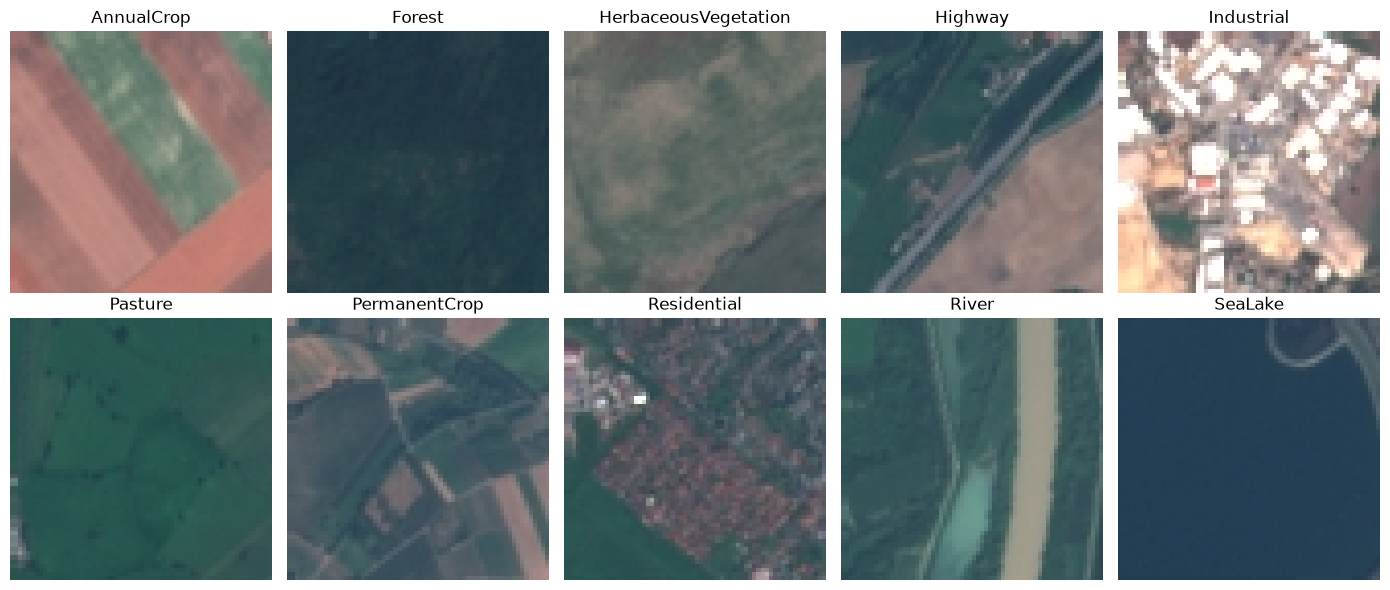

In [3]:
arr = D.load_arrays(); cls = D.classes()
fig, ax = plt.subplots(2, 5, figsize=(14, 6))
X, y, _ = arr['train']
for c, a in enumerate(ax.ravel()):
    a.imshow(X[np.where(y == c)[0][3]]); a.set_title(cls[c]); a.axis('off')
plt.tight_layout(); plt.show()

## 2. Models and training
* **baseline**: 4-block CNN from scratch, 64x64 input, 30 epochs.
* **frozen**: ImageNet ResNet-18, backbone frozen, only the new linear head trained, 128x128 input, 15 epochs.
* **finetune**: same ResNet-18, all layers trained (AdamW, one-cycle LR, label smoothing 0.1, flips/rot90/brightness-contrast aug on GPU, bf16 autocast), 128x128, 15 epochs.

Best epoch is chosen on **validation** accuracy. The test set is scored once per final model with `src/evaluate.py` (a ledger refuses re-evaluation).

In [4]:
names = {'baseline':'baseline CNN','frozen':'frozen ResNet-18','finetune':'fine-tuned ResNet-18','fix_size224_pairw2':'fine-tuned + fix'}
rows=[]
for n,l in names.items():
    t=json.load(open(f'reports/metrics/{n}_train.json')); s=json.load(open(f'reports/metrics/{n}_test.json'))
    rows.append(dict(model=l, trainable_params=t['trainable_params'], input=t['size'], best_epoch=t['best_epoch'], train_time_s=round(t['train_time_s']), val_acc=round(t['val_acc'],4), val_macro_f1=round(t['val_macro_f1'],4), test_acc=round(s['test_acc'],4), test_macro_f1=round(s['test_macro_f1'],4)))
display(pd.DataFrame(rows))
print(json.dumps(json.load(open('reports/metrics/finetune_train.json'))['hardware'], indent=1))

,model,trainable_params,input,best_epoch,train_time_s,val_acc,val_macro_f1,test_acc,test_macro_f1
0,baseline CNN,1175786,64,30,89,0.9820,0.9813,0.9817,0.9814
1,frozen ResNet-18,5130,128,12,52,0.9200,0.9173,0.9286,0.9255
2,fine-tuned ResNet-18,11181642,128,15,93,0.9862,0.9858,0.9877,0.9873
3,fine-tuned + fix,11181642,224,12,218,0.9884,0.9879,0.9894,0.9891


{
 "gpu": "NVIDIA GeForce RTX 5070 Laptop GPU",
 "gpu_mem_gb": 7.9,
 "cpu": "Intel64 Family 6 Model 198 Stepping 2, GenuineIntel",
 "cpu_count": 24,
 "ram_gb": 31.4,
 "torch": "2.11.0+cu128",
 "cuda": "12.8",
 "python": "3.13.14",
 "os": "Windows-11-10.0.26300-SP0"
}


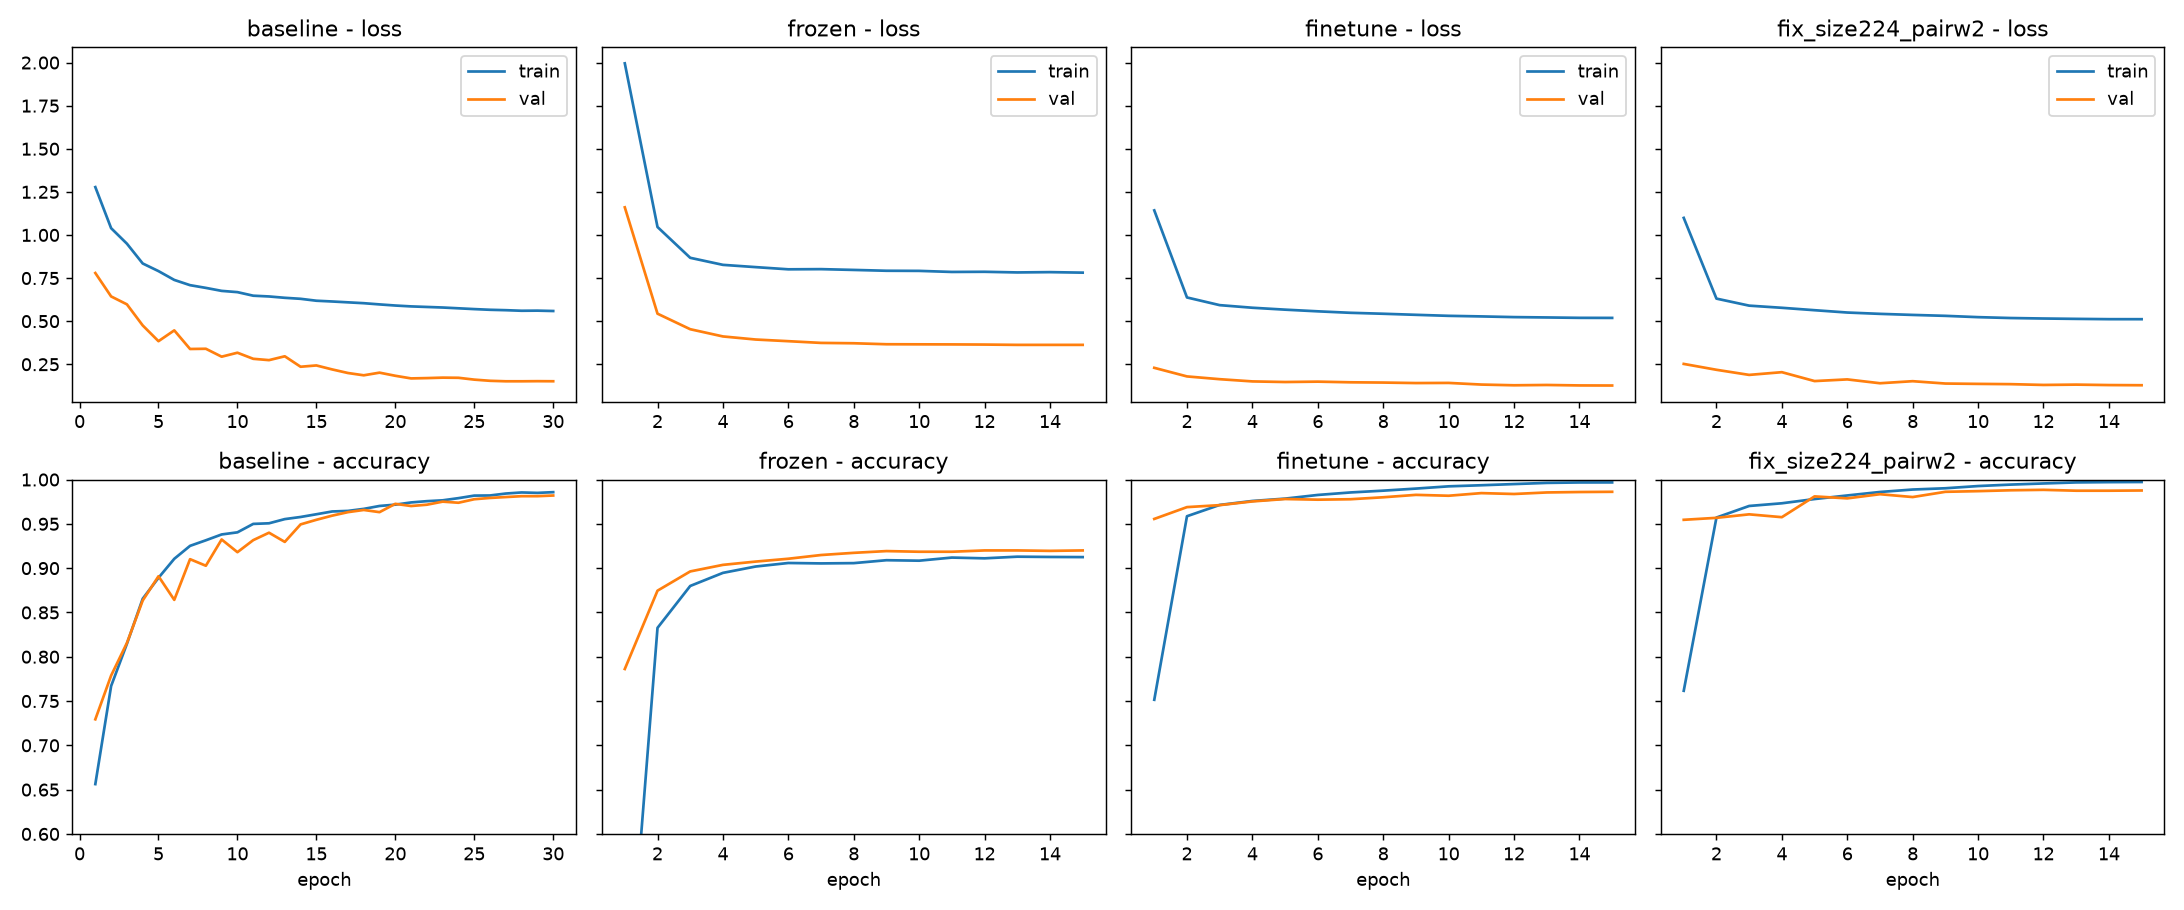

In [5]:
from IPython.display import Image, display
display(Image('reports/figures/training_curves.png'))

## 3. Error analysis (validation) and the fix
The most confused pair for the fine-tuned model on **validation** was AnnualCrop <-> PermanentCrop. Candidate fixes were compared on validation only:

In [6]:
from sklearn.metrics import confusion_matrix
yv = arr['val'][1]; a, b = cls.index('AnnualCrop'), cls.index('PermanentCrop')
r=[]
for n,d in [('finetune','fine-tuned, no fix (128px)'),('fix_pairw2','pair loss-weight x2'),('fix_size224','224px input'),('fix_size224_pairw2','224px + pair weight x2')]:
    p=np.load(f'reports/metrics/{n}_val_probs.npy').argmax(1); cm=confusion_matrix(yv,p)
    r.append(dict(candidate=d, val_acc=round((p==yv).mean(),4), annual_permanent_errors=int(cm[a,b]+cm[b,a])))
display(pd.DataFrame(r))

,candidate,val_acc,annual_permanent_errors
0,"fine-tuned, no fix (128px)",0.9862,15
1,pair loss-weight x2,0.9872,11
2,224px input,0.9884,12
3,224px + pair weight x2,0.9884,9


Chosen: **224px input + 2x loss weight on the two crop classes** (fewest pair errors, best val accuracy). Only now is it scored on test, next to the unchanged fine-tuned model.

finetune test acc 0.9877 macroF1 0.9873 | AnnualCrop<->PermanentCrop errors: 16 (AC->PC 6, PC->AC 10)
fix_size224_pairw2 test acc 0.9894 macroF1 0.9891 | AnnualCrop<->PermanentCrop errors: 11 (AC->PC 6, PC->AC 5)


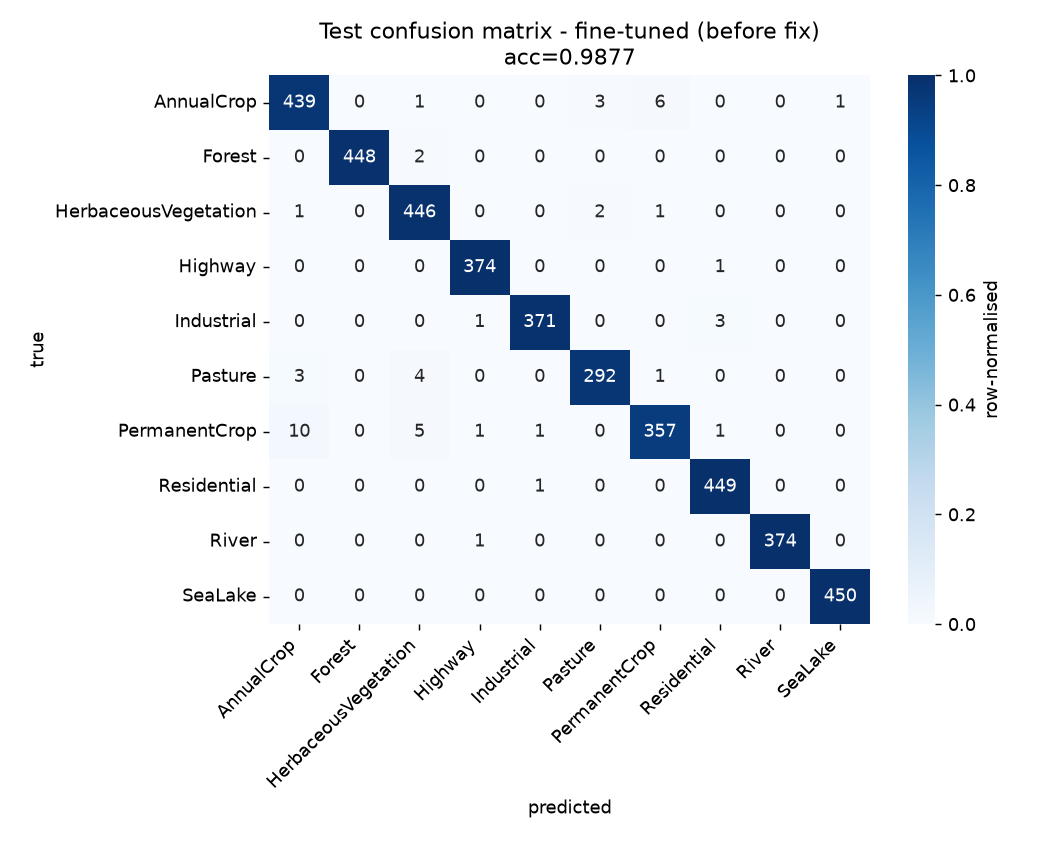

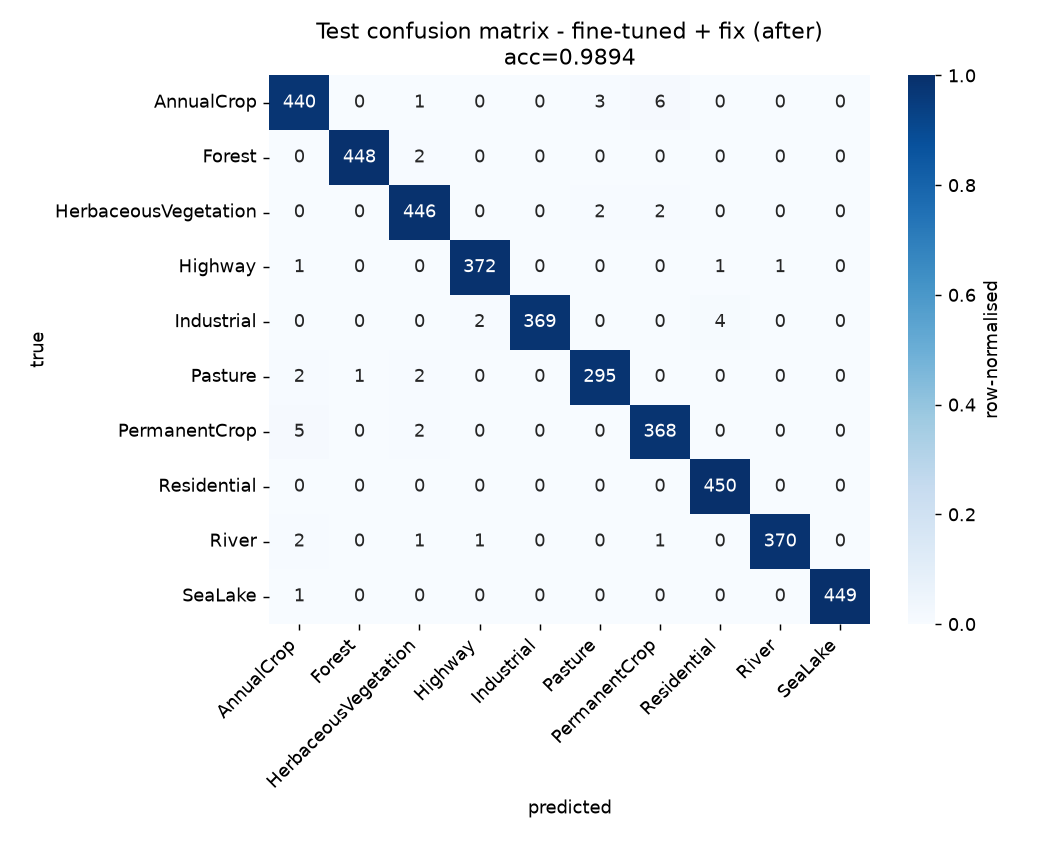

In [7]:
for n in ['finetune','fix_size224_pairw2']:
    s=json.load(open(f'reports/metrics/{n}_test.json')); cm=np.array(s['confusion_matrix'])
    print(n, 'test acc %.4f'%s['test_acc'], 'macroF1 %.4f'%s['test_macro_f1'], '| AnnualCrop<->PermanentCrop errors:', cm[a,b]+cm[b,a], '(AC->PC %d, PC->AC %d)'%(cm[a,b],cm[b,a]))
display(Image('reports/figures/confusion_matrix_before.png')); display(Image('reports/figures/confusion_matrix_after.png'))

## 4. Grad-CAM
Heat-maps from ResNet-18 `layer4` of the final model. Correct crop predictions focus on field-parcel interiors/boundaries; the misclassified crop tiles show diffuse attention on parcel texture - the two classes differ in subtle texture/row structure, which explains the confusion.

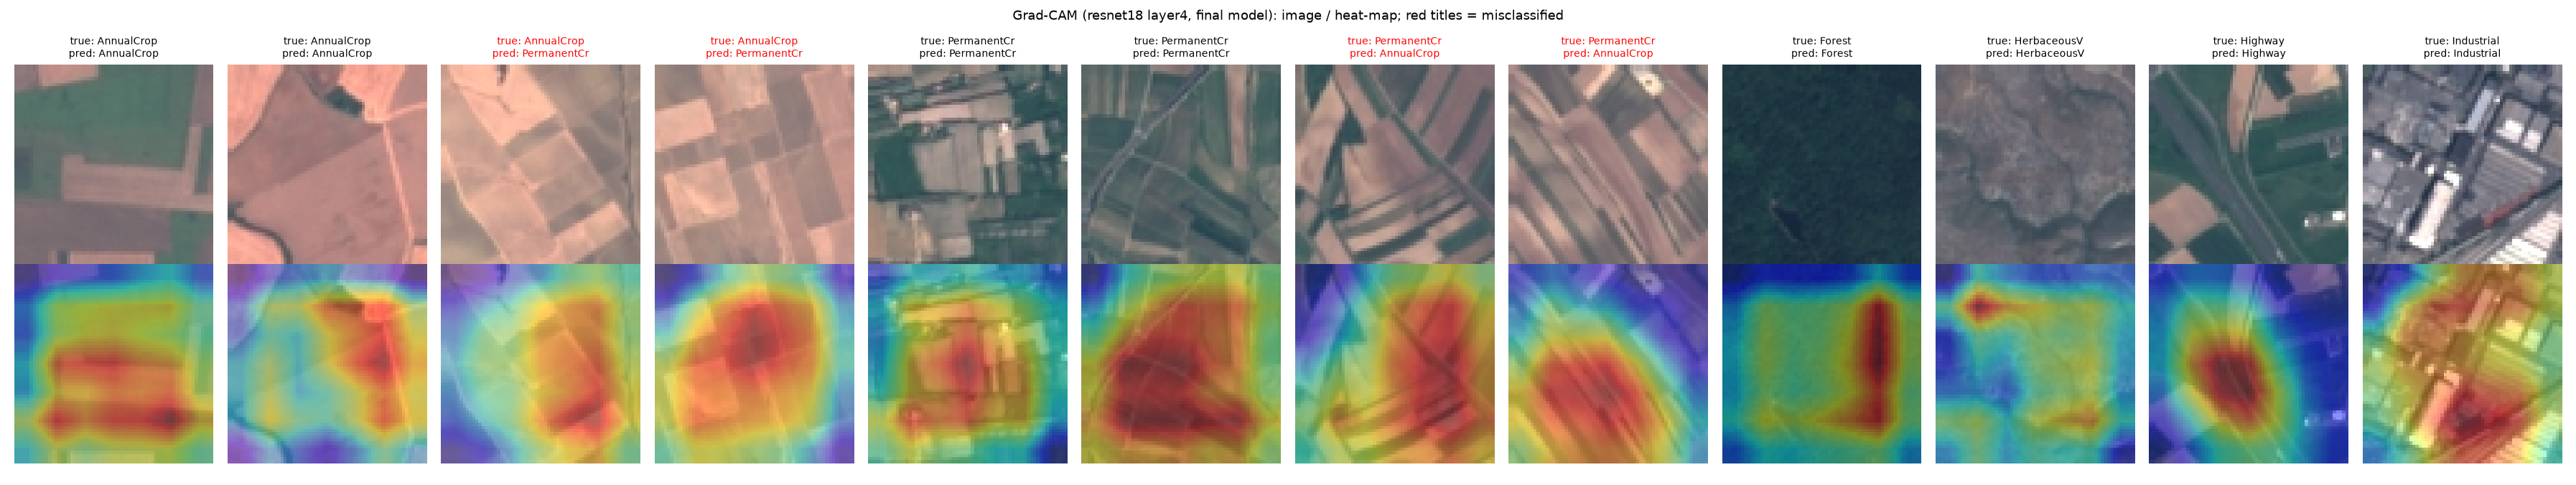

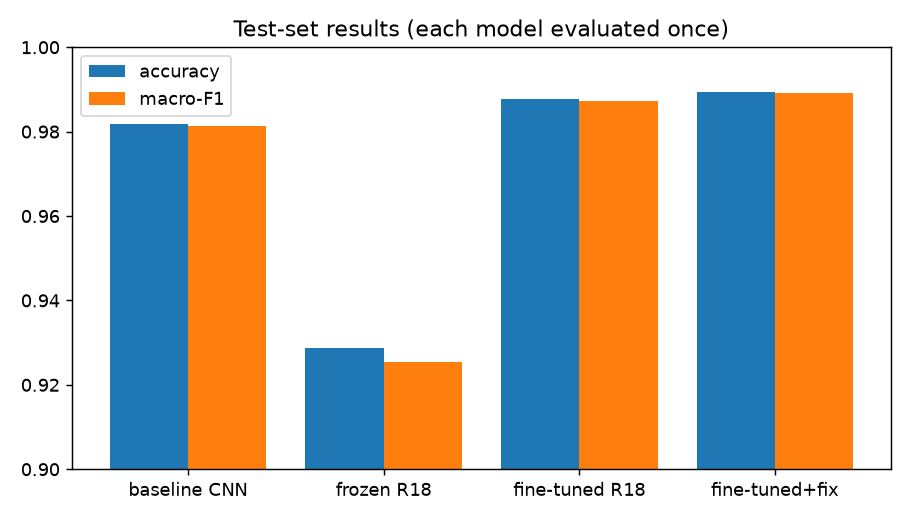

In [8]:
display(Image('reports/figures/gradcam.png')); display(Image('reports/figures/model_comparison.png'))

## 5. Deployment
The final model is exported to ONNX (`models/eurosat_resnet18.onnx`, max logit difference vs PyTorch 7e-7) and served by FastAPI (`app/main.py`, `POST /predict`) in the Dockerfile image.

In [9]:
import onnxruntime as ort, time
sess = ort.InferenceSession('models/eurosat_resnet18.onnx', providers=['CPUExecutionProvider'])
x = np.random.randn(1,3,224,224).astype('float32'); t=time.time()
for _ in range(20): sess.run(None, {'image': x})
print('ONNX CPU latency per image: %.1f ms'%((time.time()-t)/20*1000))

ONNX CPU latency per image: 9.0 ms
